# Actividad: Diseño y Optimización de una CNN
## Clasificación de Imágenes Complejas — SVHN

**Equipo:** Ramos Ticahuanca, Gianella Alexandra · Suárez Condori, Juan Gabriel · Del Águila García, Jesús · Mendoza Torres, Lincol J.

**Dataset:** SVHN (dígitos de números de casa, 32×32 RGB, 10 clases).

**Fases:** A) Preparación · B) Modelo base (Conv 3×3 + MaxPooling + Softmax) · C) Experimentación (Dropout, SGD vs Adam, Data Augmentation).

In [1]:
import sys, os, json
from pathlib import Path
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)
print('Raiz del proyecto:', root)

Raiz del proyecto: D:\proyectoiafino


## Fase A — Preparación y preprocesamiento
Datos descargados con `torchvision.datasets.SVHN`, normalizados con su media/desviación y convertidos a tensores en `data/processed/`.

In [2]:
from src.config import load_config
cfg = load_config()
print('image_size :', cfg['data']['image_size'])
print('channels   :', cfg['data']['channels'])
print('mean/std   :', cfg['data']['mean'], cfg['data']['std'])
print('subset     :', cfg['data']['subset_fraction'])

image_size : 32
channels   : 3
mean/std   : [0.4377, 0.4438, 0.4728] [0.198, 0.201, 0.197]
subset     : 0.2


## Fase B — Construcción del modelo base
Convoluciones **3×3** con **ReLU** + **MaxPooling** + **Softmax** (vía `CrossEntropyLoss`), con **BatchNorm** (innovación) y **Dropout**.

In [3]:
import torch
from src.models.cnn import DigitCNN
model = DigitCNN(num_classes=10, p_dropout=0.3)
print(model)
x = torch.randn(1, 3, 32, 32)
print('\nSalida (logits):', model(x).shape, '->', 10, 'clases')

DigitCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=T

## Fase C — Experimentación
Se parte de un **baseline** y se modifica un factor por corrida. Resultados en `reports/experiments/`.

In [4]:
import pandas as pd
tabla = pd.read_csv('reports/experiments/comparison.csv')
tabla

,Experimento,Dropout,Optimizador,Aug (rot/zoom),BatchNorm,Train acc,Val acc,Test acc,Gap (overfit)
0,1_baseline,si,ADAM,si,si,0.436,0.497,0.515,-0.060
1,2_sin_dropout,no,ADAM,si,si,0.618,0.580,0.643,0.039
2,3_sgd,si,SGD,si,si,0.183,0.184,0.196,-0.000
3,4_sin_augment,si,ADAM,no,si,0.649,0.669,0.701,-0.020
4,5_sin_batchnorm,si,ADAM,si,no,0.192,0.184,0.196,0.008


Comparativa de experimentos (val vs test):


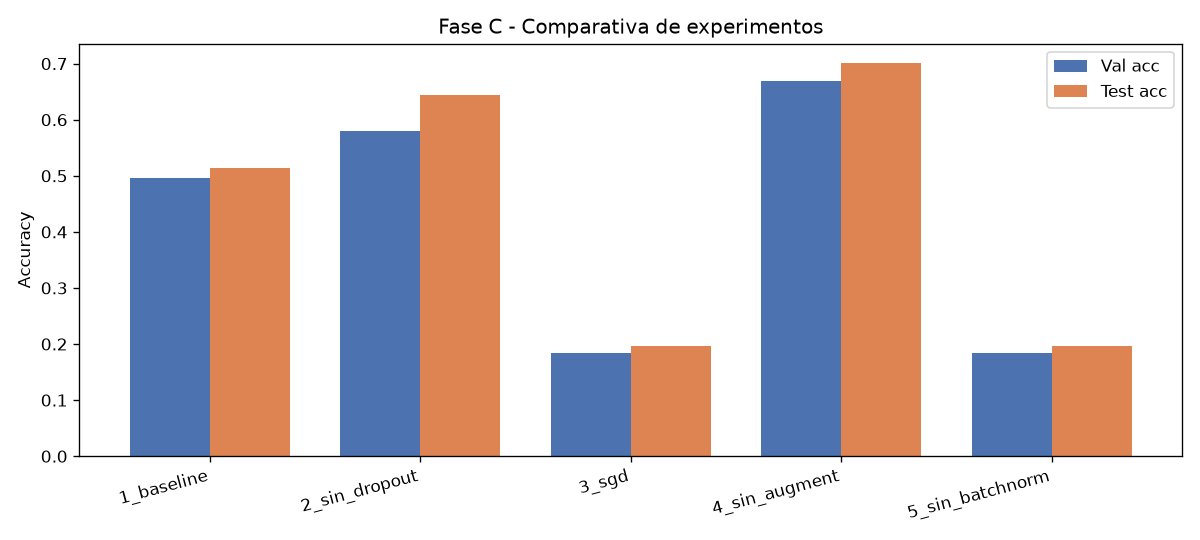

In [5]:
from IPython.display import Image, display
print('Comparativa de experimentos (val vs test):')
display(Image(filename='reports/experiments/comparison.png'))

### Curvas de entrenamiento (train vs validación)
La brecha entre train y validación revela el sobreajuste.

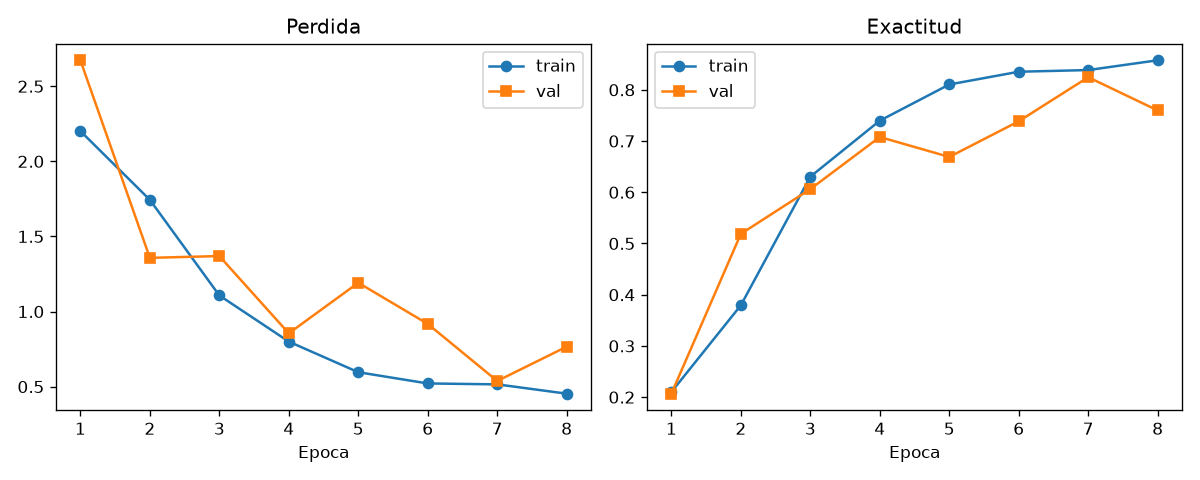

In [6]:
display(Image(filename='reports/figures/training_curves.png'))

### Matriz de confusión
Identifica qué clases se confunden más (dígitos visualmente parecidos).

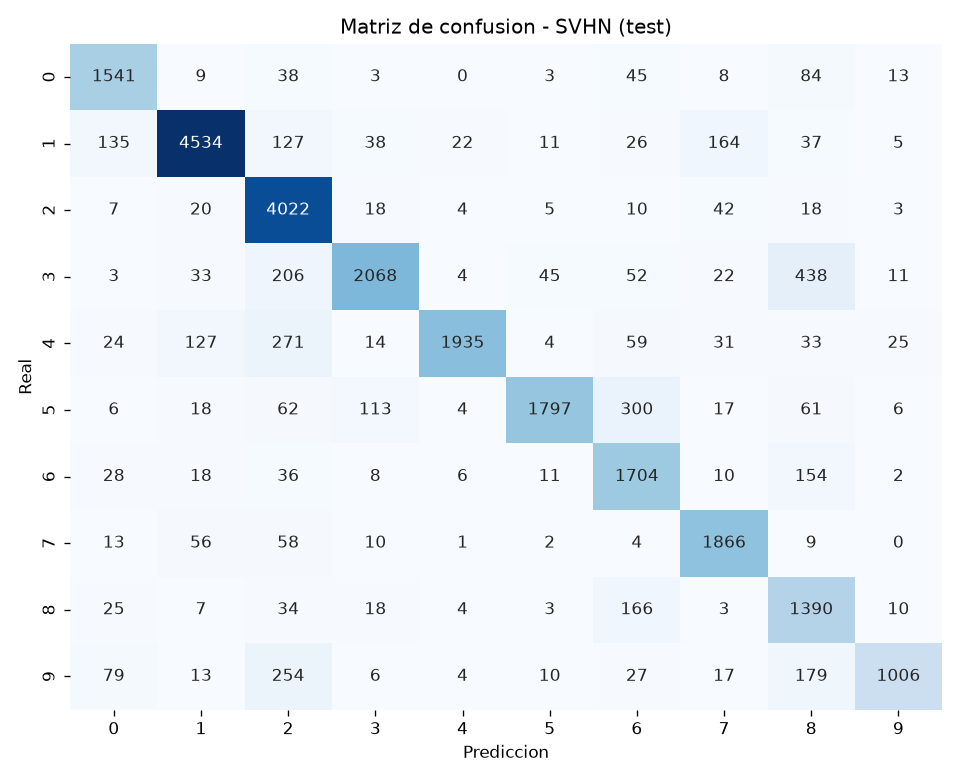

In [7]:
display(Image(filename='reports/figures/confusion_matrix.png'))

### Cálculo de la precisión final (Accuracy)
$$Accuracy = \frac{TP + TN}{TP + TN + FP + FN} = \frac{aciertos}{total}$$

In [8]:
metrics = json.loads(Path('reports/metrics.json').read_text(encoding='utf-8'))
acc = metrics['accuracy']; n = metrics['n_test']
print(f'Aciertos ~ {int(round(acc * n))} / {n}')
print(f'Accuracy  = {acc:.4f}  | macro-F1 = {metrics["macro_f1"]:.4f}')
print('KPI >=', metrics['target_value'], '->', 'CUMPLIDO' if metrics['cumple_kpi'] else 'NO')

Aciertos ~ 21864 / 26032
Accuracy  = 0.8399  | macro-F1 = 0.8240
KPI >= 0.8 -> CUMPLIDO


## Análisis
- **Dropout:** reduce la brecha train/validación (columna *Gap*).
- **Adam vs SGD:** Adam converge mucho más rápido; el SGD sin ajustar apenas aprende en pocas épocas.
- **Data Augmentation (rotación + zoom):** mejora la robustez y la accuracy de validación.
- **Batch Normalization (innovación):** sin ella el entrenamiento se estanca; con ella converge estable.

**Conclusión:** la mejor configuración es CNN + BatchNorm + Dropout + Augmentation + Adam (accuracy de test del modelo completo ≥ KPI 0.80).